# 05 · Inspecting the shipped hierarchies

An interactive-free, static walk through what `make build` wrote to `out/`. The sections:
1. What each snapshot's hierarchy contains.
2. One snapshot drawn as an icicle, with its top-level super-nodes.
3. What structure each coarse level keeps, compared with partitions into the same numbers of groups that encode no clustering (notebook 03, section 7).
4. Labels and glosses, what the labeller saw, how the judges rated them, and a per-super-node coherence read-out against citations.
5. How the hierarchy evolves across snapshots at each level.
6. One retrieval question traced through the drill-down, against the flat, PageRank and popularity baselines.

Change the parameters in the next cell to inspect another snapshot, super-node or question. The aggregate evaluation is in `report.md`; this notebook is for looking at individual cases. A single example says nothing about the averages.

In [1]:
SNAPSHOT = 2026      # snapshot to inspect (one of the config cutoffs)
LABEL_LEVEL = 0      # level whose labels are tabulated in section 4 (0 or 1)
EXAMPLE_SN = None    # super-node id for the close-up in section 4 (None: the largest at LABEL_LEVEL)
QUESTION = "Q3"      # ground-truth question traced in section 6 (a favourable example; try Q1, Q8, Q14)

In [2]:
from pathlib import Path
from collections import Counter
import json, os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from tkh.config import load_config
from tkh.io import load, snapshot
from tkh.semantic import CONCEPT_TYPES
from tkh.coarsen import node_papers
from scripts.visualize import icicle

pd.set_option("display.max_colwidth", 90)
cfg = load_config(os.environ.get("TKH_CONFIG"))
tkh = load(cfg)
OUT = Path(cfg.out_dir)
hier = {c: json.loads((OUT / str(c) / "hierarchy.json").read_text()) for c in cfg.cutoffs}
events = json.loads((OUT / "temporal_events.json").read_text())["events"]
ntype = tkh.nodes["type"].to_dict()
name = tkh.nodes["surface_form"].to_dict()
is_concept = lambda v: ntype[v] in CONCEPT_TYPES
sn = {c: {s["id"]: s for s in h["supernodes"]} for c, h in hier.items()}
print("snapshots:", list(hier), "| run:", json.loads((OUT / "run_info.json").read_text())["cid"])

snapshots: [2020, 2022, 2024, 2026] | run: a0.5_g0.5_r2_native_d100_h0.2


## 1 · What the snapshots contain

For every snapshot and level: the number of super-nodes, their sizes in concept nodes (anchored nodes such as articles and claims ride along, but are not counted), and how many carry labels.

In [3]:
rows = []
for c, h in hier.items():
    for k in range(h["levels"]):
        s = [x for x in h["supernodes"] if x["level"] == k]
        size = np.array([sum(map(is_concept, x["member_ids"])) for x in s])
        rows.append({"snapshot": c, "level": k, "budget": h["budgets"][k], "super-nodes": len(s),
                     "concept nodes": size.sum(), "all nodes": sum(len(x["member_ids"]) for x in s),
                     "median size": np.median(size), "largest": size.max(), "largest share": size.max() / size.sum(),
                     "labelled": sum(bool(x["label"]) for x in s)})
pd.DataFrame(rows).set_index(["snapshot", "level"]).round(3)

budget  super-nodes  concept nodes  all nodes  median size  \
snapshot level                                                               
2020     0          15           15           1018       1475         49.0   
         1          60           60           1018       1475         15.5   
         2         240          240           1018       1475          4.0   
2022     0          15           15           1464       2144        111.0   
         1          60           60           1464       2144         26.5   
         2         240          240           1464       2144          6.0   
2024     0          15           15           2829       4094        154.0   
         1          60           60           2829       4094         50.5   
         2         240          240           2829       4094         10.0   
2026     0          15           15           3980       5798        222.0   
         1          60           60           3980       5798         76.0   
         2         240          240           3980       5798         16.0   

                largest  largest share  labelled  
snapshot level                                    
2020     0          135          0.133        15  
         1           33          0.032        60  
         2            8          0.008         0  
2022     0          184          0.126        15  
         1           48          0.033        60  
         2           12          0.008         0  
2024     0          360          0.127        15  
         1           90          0.032        60  
         2           23          0.008         0  
2026     0          503          0.126        15  
         1          132          0.033        60  
         2           33          0.008         0

## 2 · One snapshot as an icicle

One row per level, level 0 on top. Each box is a super-node, as wide as its number of concept nodes and placed under its parent, so nesting (P1) is visible. Colour marks the level-0 ancestor.

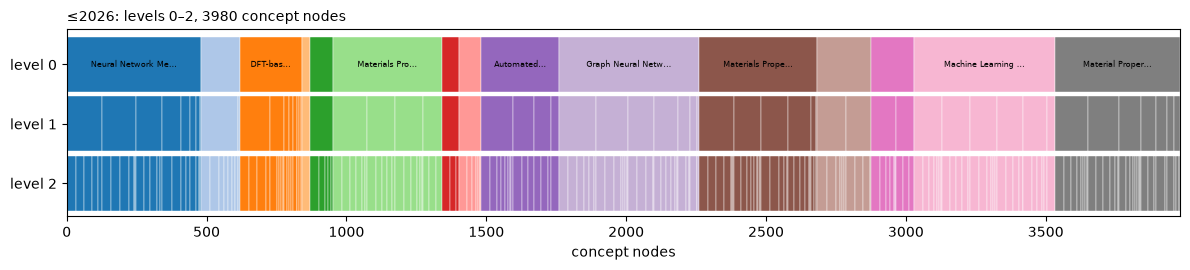

In [4]:
h = hier[SNAPSHOT]
concept = {v for s in h["supernodes"] if s["level"] == 0 for v in s["member_ids"] if is_concept(v)}
roots = sorted(s["id"] for s in h["supernodes"] if s["level"] == 0)
cmap = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(12, 2.8))
icicle(ax, h, concept, lambda r, s: cmap(roots.index(r) % 20))
ax.set_title(f"≤{SNAPSHOT}: levels 0–2, {len(concept)} concept nodes", loc="left", fontsize=10)
fig.tight_layout()

In [5]:
def composition(members):
    t = Counter(ntype[v] for v in members if is_concept(v))
    n = sum(t.values())
    return ", ".join(f"{k} {v / n:.0%}" for k, v in t.most_common(3))

papers = node_papers(tkh, snapshot(tkh, SNAPSHOT))
top0 = []
for s in sorted((x for x in h["supernodes"] if x["level"] == 0), key=lambda x: -sum(map(is_concept, x["member_ids"]))):
    mem = [v for v in s["member_ids"] if is_concept(v)]
    widest = sorted(mem, key=lambda v: (-len(papers.get(v, ())), name[v]))[:4]
    top0.append({"id": s["id"], "label": s["label"], "concept nodes": len(mem),
                 "children": sum(x["parent_id"] == s["id"] for x in h["supernodes"]),
                 "types": composition(mem), "most-shared members": "; ".join(name[v] for v in widest)})
pd.DataFrame(top0).set_index("id")

,label,concept nodes,children,types,most-shared members
id,,,,,
L0.8,Machine Learning Tasks,503,6,"method 26%, component 23%, technique 18%",materials science; MACE-MP-0; machine learning; LAMMPS
L0.4,Graph Neural Networks,499,7,"task 24%, problem 19%, technique 17%",Molecular dynamics simulations; Neural Equivariant Interatomic Potentials; atomistic s...
L0.1,Neural Network Methods,480,8,"component 29%, method 24%, technique 23%",SchNet; ACE with message passing; Message Passing Neural Network; DimeNet
L0.9,Material Property Prediction,448,7,"task 54%, technique 20%, problem 20%",Formation energy prediction; Stress prediction; atomic force prediction; Accelerated m...
L0.5,Materials Property Prediction,425,6,"task 32%, technique 22%, problem 19%",computational chemistry; molecular dynamics; Force prediction; Energy prediction
L0.16,Materials Property Prediction,390,4,"component 35%, technique 21%, problem 18%",MAE; density functional theory; condensed matter physics; Materials Project
L0.3,Automated ML Pipelines,278,4,"technique 47%, component 40%, problem 7%",Huber loss; Learning rate scheduling; embedding layer; Matminer
L0.11,DFT-based tasks,222,8,"task 35%, technique 33%, problem 16%",Geometry optimization; phonon calculations; thermal conductivity prediction; High-thro...
L0.6,Li-ion Diffusion Modeling,191,2,"technique 25%, component 23%, dataset 18%",F1; eSEN; Gaussian radial basis functions; Ionic conductivity prediction


## 3 · What structure the coarse levels keep

At a coarser level the method recomputes its structural score on the **collapsed incidence**: for every fine hyper-edge, which super-nodes it touches (the T4 rule). The score uses presence only; endpoint counts are kept as metadata but not scored. This section measures what that representation keeps in the shipped hierarchy at ≤2026. Notebook 03 (section 7) gives the same statistics for **reference partitions** that encode no clustering; here they are shown side by side, on the same concept-relation hypergraph, at the same numbers of groups.
- **Internal edges:** fine edges that fall inside one super-node.
- **Multi-way edges:** coarse edges that still touch three or more super-nodes, which a pairwise projection would split.
- **Presence vs counts:** how closely the presence-based gain the method uses ranks super-node pairs like a count-based alternative.
- **Density:** the share of super-node pairs with any shared edge.
- **Paper coverage:** how many papers a super-node touches, and how closely that simply tracks super-node size.

In [6]:
from tkh import structure as st
from tkh.evaluate.stability import read_partitions
from tkh.hierarchy import concept_only

C4 = max(cfg.cutoffs)
snap4 = snapshot(tkh, C4)
items, Binc, _, edge_rel = st.concept_incidence(tkh, snap4, max_paper_share=0.2)
aff = {"method (inverse-size)": 1 / (Binc.sum(axis=0) - 1), "uniform": np.ones(Binc.shape[1])}   # the method's weights, and equal weights
pap4 = st.node_papers(tkh, snap4)
item_papers = [pap4[v] for v in items]
shipped = concept_only(read_partitions(OUT, [C4]), tkh)[C4]
pos = {v: i for i, v in enumerate(items)}
rows = []
for k, lv in enumerate(shipped):
    lab = np.empty(len(items), int)
    for g, key in enumerate(sorted(lv)):
        lab[[pos[v] for v in lv[key] if v in pos]] = g        # hub concept nodes carry no edge and are not items
    s_ = st.collapse_stats(lab, Binc, item_papers=item_papers, n_papers=len(snap4.articles), affinity_weights=aff)
    rows.append({"level": k, "partition": "shipped (SHAC-T)", **s_})
    for kind in ("random", "paper"):
        ref = pd.DataFrame([st.collapse_stats(st.reference_partition(kind, items, len(lv), tkh, seed, snap4), Binc,
                                              item_papers=item_papers, n_papers=len(snap4.articles), affinity_weights=aff)
                            for seed in range(20)]).mean()
        rows.append({"level": k, "partition": f"{kind} reference (mean of 20)", **ref.to_dict()})
coarse = pd.DataFrame(rows).set_index(["level", "partition"]).drop(columns="groups")
coarse.round(3)

internal edges  \
level partition                                       
0     shipped (SHAC-T)                        0.258   
      random reference (mean of 20)           0.005   
      paper reference (mean of 20)            0.640   
1     shipped (SHAC-T)                        0.148   
      random reference (mean of 20)           0.002   
      paper reference (mean of 20)            0.536   
2     shipped (SHAC-T)                        0.061   
      random reference (mean of 20)           0.000   
      paper reference (mean of 20)            0.034   

                                     multi-way among linking edges  \
level partition                                                      
0     shipped (SHAC-T)                                       0.336   
      random reference (mean of 20)                          0.855   
      paper reference (mean of 20)                           0.431   
1     shipped (SHAC-T)                                       0.345   
      random reference (mean of 20)                          0.911   
      paper reference (mean of 20)                           0.455   
2     shipped (SHAC-T)                                       0.463   
      random reference (mean of 20)                          0.928   
      paper reference (mean of 20)                           0.711   

                                     projection pairs per multi-way edge  \
level partition                                                            
0     shipped (SHAC-T)                                             4.391   
      random reference (mean of 20)                               25.465   
      paper reference (mean of 20)                                 8.417   
1     shipped (SHAC-T)                                             6.129   
      random reference (mean of 20)                               64.538   
      paper reference (mean of 20)                                11.414   
2     shipped (SHAC-T)                                             7.871   
      random reference (mean of 20)                               87.762   
      paper reference (mean of 20)                                17.303   

                                     group pairs sharing an edge  \
level partition                                                    
0     shipped (SHAC-T)                                     0.781   
      random reference (mean of 20)                        1.000   
      paper reference (mean of 20)                         0.976   
1     shipped (SHAC-T)                                     0.269   
      random reference (mean of 20)                        1.000   
      paper reference (mean of 20)                         0.373   
2     shipped (SHAC-T)                                     0.048   
      random reference (mean of 20)                        0.805   
      paper reference (mean of 20)                         0.116   

                                     Spearman(presence, counts), method (inverse-size) weights  \
level partition                                                                                  
0     shipped (SHAC-T)                                                                   0.421   
      random reference (mean of 20)                                                      0.669   
      paper reference (mean of 20)                                                       0.724   
1     shipped (SHAC-T)                                                                   0.555   
      random reference (mean of 20)                                                      0.932   
      paper reference (mean of 20)                                                       0.638   
2     shipped (SHAC-T)                                                                   0.732   
      random reference (mean of 20)                                                      0.971   
      paper reference (mean of 20)                                                       0.820

**Reading:**
- **On paper coverage the shipped levels look like paper-preserving groupings.** A typical super-node touches about as many papers as a group of whole papers, far fewer than a random group with the same number of groups.
- **Edge absorption.**
  - At levels 0 and 1 the shipped levels absorb far fewer edges than paper-preserving groupings.
  - At level 2 they absorb somewhat more (see the table).
  - At every level they absorb far more than random groupings.
  - This is consistent with the method mixing nodes of different papers by name similarity, while its structural term keeps much of each paper's star together.
- **Their linking structure is sparser than both references.** Fewer super-node pairs share an edge. Fewer linking edges stay multi-way, and each creates fewer pairs. Multi-way edges remain a substantial share all the same. That is the evidence that keeping the collapsed incidence, rather than a pairwise super-node graph, matters.
- **Structure densifies steeply towards level 0.** At the top level most super-node pairs share some edge. The method normalises its structural score per level; that normalisation is mainly motivated by the incomparable scales of the two signals (`docs/formal_statement.md`), and this densification is a further reason.
- **Presence and counts diverge, and how much depends on the weighting.**
  - Under the method's inverse-size weights, the shipped levels' presence- and count-based rankings disagree more than in either reference, and most at level 0. There the method's presence-based gain discards multiplicity where the two disagree most.
  - With equal weights the shipped levels no longer stand out: some references disagree as much or more (random at level 0, paper-preserving at level 1). So the divergence is as much a property of the weighting as of the hierarchy.
  - Whether a count-based gain would build better super-nodes is untested (notebook 03, section 9 (B2)).
- **Paper coverage tracks size in the shipped hierarchy.**
  - Random groups have almost equal sizes, so their correlation says nothing.
  - Paper-preserving groups vary in size, yet their coverage barely tracks it.
  - Shipped super-nodes' coverage tracks size closely, so as a coarse "hub" signal coverage would largely duplicate the size cap.

## 4 · Labels, what produced them, and how coherent the super-nodes are

For every labelled super-node at `LABEL_LEVEL` the table shows:
- **label and gloss**, written by the labeller from the *shown* half of the members only (`label_inputs.json`);
- **forced choice**, i.e. whether each judge picked this label among four from the *held-out* half (✓ / ✗; post-hoc instrument, see `report.md`);
- **flags** from the deterministic checks;
- **paper purity**, the share of members from the super-node's most common paper;
- **coupling lift**, the citation coupling between the papers its members come from, relative to the average pair of citing papers. This is the E1a ruler restricted to one super-node: 1 means no more coupled than chance. It is noisy for small super-nodes and undefined (–) when fewer than two of its papers cite anything.

In [7]:
from tkh.evaluate.coherence import Ruler
inputs = json.loads((OUT / str(SNAPSHOT) / "label_inputs.json").read_text())
judg = json.loads((OUT / "label_judgements.json").read_text())
fc = {(r["id"], r["judge"]): r["hit"] for r in judg if r.get("variant") == "model" and r["snapshot"] == SNAPSHOT}
flags = {r["id"]: r for r in judg if r.get("pass") == "held_out" and r["snapshot"] == SNAPSHOT}
judges = sorted({j for _, j in fc})
ruler = Ruler(tkh, SNAPSHOT)
C = ruler.coupling(ruler.papers)
pidx = {a: i for i, a in enumerate(ruler.papers)}
iu = np.triu_indices(len(ruler.papers), 1)
mean_c = C[iu].mean()

def coupling_lift(members):
    n = Counter(ruler.single[v] for v in members if v in ruler.single and ruler.single[v] in pidx)
    ps = sorted(n, key=pidx.get)
    if len(ps) < 2:
        return np.nan
    w = np.array([[n[p] * n[q] for q in ps] for p in ps], float)
    c = C[np.ix_([pidx[p] for p in ps], [pidx[p] for p in ps])]
    m = np.triu_indices(len(ps), 1)
    return float((w[m] * c[m]).sum() / (w[m].sum() * mean_c))

def paper_purity(members):
    first = Counter(min(papers[v], key=str) for v in members if papers.get(v))
    return max(first.values()) / sum(first.values()) if first else np.nan

rows = []
for s in sorted((x for x in h["supernodes"] if x["level"] == LABEL_LEVEL), key=lambda x: -sum(map(is_concept, x["member_ids"]))):
    mem = [v for v in s["member_ids"] if is_concept(v)]
    f = flags.get(s["id"], {})
    rows.append({"id": s["id"], "label": s["label"], "gloss": s["gloss"], "n": len(mem),
                 **{j.split(":")[0]: "✓" if fc.get((s["id"], j)) else "✗" for j in judges},
                 "flags": "; ".join(f.get("det_named_non_member_ids", [])) or "",
                 "paper purity": paper_purity(mem), "coupling lift": coupling_lift(mem)})
labels_df = pd.DataFrame(rows).set_index("id")
labels_df.round(2)

,label,gloss,n,gemma2,llama3.1,phi4,flags,paper purity,coupling lift
id,,,,,,,,,
L0.8,Machine Learning Tasks,Includes various tasks in materials and chemistry.,503,✓,✓,✓,,0.09,1.05
L0.4,Graph Neural Networks,Methods using graph neural networks for materials science.,499,✓,✗,✓,,0.17,1.02
L0.1,Neural Network Methods,Models for materials and chemistry tasks.,480,✓,✓,✓,,0.08,1.22
L0.9,Material Property Prediction,Tasks predicting various material properties using ML.,448,✗,✗,✗,,0.10,0.87
L0.5,Materials Property Prediction,Tasks and methods for predicting various material properties.,425,✓,✗,✓,,0.10,0.84
L0.16,Materials Property Prediction,"Metrics, tasks, and components for predicting material properties.",390,✗,✗,✗,,0.15,1.18
L0.3,Automated ML Pipelines,Techniques and components for automating machine learning workflows in materials science.,278,✓,✓,✓,,0.26,1.18
L0.11,DFT-based tasks,Tasks related to density functional theory calculations.,222,✓,✗,✗,,0.27,0.91
L0.6,Li-ion Diffusion Modeling,Tasks related to simulating lithium ion diffusion in materials.,191,✗,✗,✗,,0.27,1.45


In [8]:
s_id = EXAMPLE_SN or labels_df.index[0]
s = sn[SNAPSHOT][s_id]
inp = inputs[s_id]
print(f"{s_id} (level {s['level']}): {s['label']}\n  gloss: {s['gloss']}\n")
print(f"labeller saw {len(inp['shown'])} of the members (highest paper count first):")
print("  " + "; ".join(f"{name[v]} [{ntype[v]}]" for v in inp["shown"][:20]) + (" …" if len(inp["shown"]) > 20 else ""))
print(f"\njudge saw the {len(inp['held_out'])} held-out members, e.g.:")
print("  " + "; ".join(f"{name[v]} [{ntype[v]}]" for v in inp["held_out"][:20]) + (" …" if len(inp["held_out"]) > 20 else ""))
print("\nforced-choice reasons:")
for r in judg:
    if r.get("variant") == "model" and r["snapshot"] == SNAPSHOT and r["id"] == s_id:
        print(f"  {r['judge']:12s} {'picked it' if r['hit'] else 'missed'}: {r['reason']}")

L0.8 (level 0): Machine Learning Tasks
  gloss: Includes various tasks in materials and chemistry.

labeller saw 40 of the members (highest paper count first):
  machine learning [task]; Oriented FAST and Rotated BRIEF [method]; Random Forest [method]; DFT+U [method]; PBE functional [method]; Quantum Espresso [method]; Vienna Ab‑initio simulation package [method]; projector-augmented wave [method]; AMBER [method]; Atomic Simulation Environment [method]; Light Gradient-Boosting Machine [method]; MatterSim [method]; Transfer learning [technique]; atomistic machine learning [task]; machine learning for molecules [task]; model interpretability [problem]; AIMD transferability test [dataset]; Ab-initio molecular dynamics (AIMD) sampling [component]; Accelerated validation of ionic conductivity predictions [problem]; Accuracy-scale disconnect in atomistic simulations [problem] …

judge saw the 251 held-out members, e.g.:
  Breadth‑first search for minimum‑percolation‑energy [component]; Free‑

Text(0.0, 1.0, '≤2026, level 0: citation coupling inside each super-node')

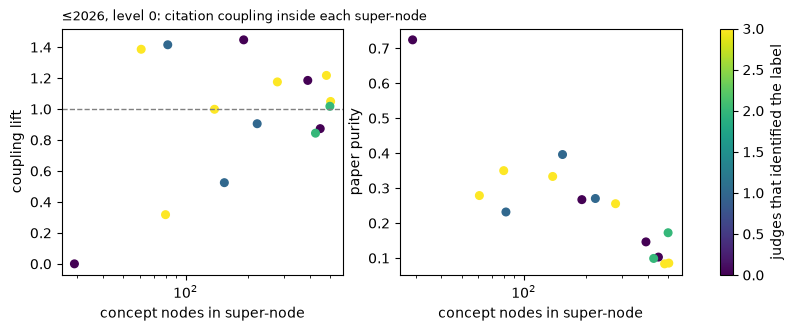

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
d = labels_df.dropna(subset=["coupling lift"])
hits = d[[j.split(":")[0] for j in judges]].eq("✓").sum(axis=1)
for ax, col in zip(axes, ["coupling lift", "paper purity"]):
    ax.scatter(d["n"], d[col], c=hits, cmap="viridis", vmin=0, vmax=len(judges), s=30)
    ax.set_xscale("log"); ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xlabel("concept nodes in super-node"); ax.set_ylabel(col)
axes[0].axhline(1, color="0.5", lw=1, ls="--")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, len(judges)))
fig.colorbar(sm, ax=axes, label="judges that identified the label")
axes[0].set_title(f"≤{SNAPSHOT}, level {LABEL_LEVEL}: citation coupling inside each super-node", fontsize=9, loc="left")

Reading the table and the plot:
- **Coupling lift** above 1 means the super-node's papers cite related work more than an average pair of papers does. Values scatter widely around 1 and are noisiest for small super-nodes. That matches the aggregate E1a result: no systematic coherence beyond chance.
- **Identification.** Most labels are identified by at least one judge. But in `report.md`, labels of randomly regrouped nodes are identified almost as often, so a ✓ says the label fits its members, not that the group is meaningful.

## 5 · Evolution across snapshots

`temporal_events.json` gives every super-node one fate per transition. There are no death events: with exact budgets, a disappearing super-node is recorded as merged into its largest-overlap successor.

event             birth  change  continue  growth  merge  split
level transition                                               
0     2020→2022       0       1         2       9      1      1
      2022→2024       0       3         0       9      1      1
      2024→2026       0       3         0      12      0      0
1     2020→2022       0       3        19      27      4      3
      2022→2024       0       5        16      28      3      4
      2024→2026       1       0        16      37      2      2
2     2020→2022      11       0       161      51     11      3
      2022→2024       4       3       120      92      9      6
      2024→2026       3       0       136      77     10      7

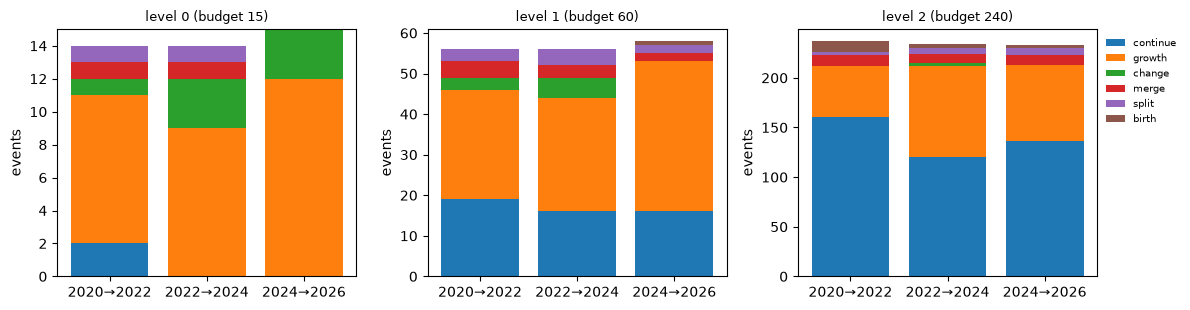

In [10]:
ev = pd.DataFrame([e for e in events if e["from_snapshot"] is not None])
ev["transition"] = ev["from_snapshot"].astype(int).astype(str) + "→" + ev["to_snapshot"].astype(int).astype(str)
counts = ev.groupby(["level", "transition", "event"]).size().unstack(fill_value=0)
kinds = [k for k in ["continue", "growth", "change", "merge", "split", "birth"] if k in counts.columns]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for k, ax in enumerate(axes):
    t = counts.loc[k, kinds]
    bottom = np.zeros(len(t))
    for i, kind in enumerate(kinds):
        ax.bar(t.index, t[kind], bottom=bottom, color=plt.get_cmap("tab10")(i), label=kind)
        bottom += t[kind].values
    ax.set_title(f"level {k} (budget {hier[SNAPSHOT]['budgets'][k]})", fontsize=9)
    ax.set_ylabel("events")
axes[-1].legend(frameon=False, fontsize=7, bbox_to_anchor=(1, 1), loc="upper left")
fig.tight_layout()
counts

In [11]:
m = json.loads((OUT / "metrics.json").read_text())["rows"]
pd.DataFrame([{"transition": r["transition"], "level": r["level"], "ARI on common nodes": r["value"],
               "95% subsample interval": f"[{r['ci_lo']:.2f}, {r['ci_hi']:.2f}]", "common nodes": r["n"]}
              for r in m if r["family"] == "E2" and r["metric"] == "cross_snapshot_ari" and r["variant"] == "model"]
             ).pivot(index="transition", columns="level", values="ARI on common nodes").round(3)

level,0,1,2
transition,,,
2020-2022,0.949,0.905,0.949
2022-2024,0.909,0.909,0.911
2024-2026,0.980,0.956,0.957


**Level-0 lineage.** Size (concept nodes) and label of each persistent level-0 id per snapshot.
- A row that continues is a persisting super-node.
- A row that starts later is the smaller child of a split. Level 0 has no births after the first snapshot.
- A row that ends was merged into its largest-overlap successor.

Labels are regenerated at every snapshot from the current members, so the label of a persistent id can change. In the shipped run some change a lot, e.g. L0.4. That is a P6-versus-P5 tension: a label that stays stable for a drifting group would be less faithful.

In [12]:
lin = {}
for c, h in hier.items():
    for s in h["supernodes"]:
        if s["level"] == 0:
            lin.setdefault(s["id"], {})[c] = (sum(map(is_concept, s["member_ids"])), s["label"])
size_tab = pd.DataFrame({i: {c: v[0] for c, v in d.items()} for i, d in lin.items()}).T.sort_index(key=lambda x: x.str[3:].astype(int))
label_tab = pd.DataFrame({i: {c: v[1] for c, v in d.items()} for i, d in lin.items()}).T.loc[size_tab.index]
display(size_tab.fillna("").astype(str).replace(r"\.0$", "", regex=True))
label_tab.fillna("")

,2020,2022,2024,2026
L0.1,124,178,308,480
L0.2,32,37,79,80
L0.3,119,119,219,278
L0.4,128,154,334,499
L0.5,121,155,302,425
L0.6,49,62,121,191
L0.7,32,54,154,154
L0.8,135,184,360,503
L0.9,82,111,321,448
L0.10,21,51,90,138


,2020,2022,2024,2026
L0.1,Graph Neural Networks,Graph Neural Networks,Graph Neural Networks,Neural Network Methods
L0.2,Descriptors and Components,Descriptors for Materials,Surrogate Models,Surrogate Models
L0.3,Automated ML for Materials,Automated ML for Materials,Automated ML Pipelines,Automated ML Pipelines
L0.4,Amorphous Carbon Simulations,Interatomic Potentials,Interatomic Potentials,Graph Neural Networks
L0.5,MD Simulation Tasks,Fracture Prediction Methods,Force Prediction Tasks,Materials Property Prediction
L0.6,Li-ion Diffusion Modeling,Diffusion Modeling Tasks,Equivariant Neural Networks,Li-ion Diffusion Modeling
L0.7,Interatomic Potential Techniques,CGCNN Models,Interatomic Potential Models,Force Prediction Methods
L0.8,DFT-Based Methods,Machine Learning Techniques,Interatomic Potentials,Machine Learning Tasks
L0.9,Crystal Structure Prediction,Property Prediction Challenges,Material Property Prediction,Material Property Prediction
L0.10,Materials Property Datasets,Molecular Dynamics Simulations,Materials Datasets,DFT-based Properties


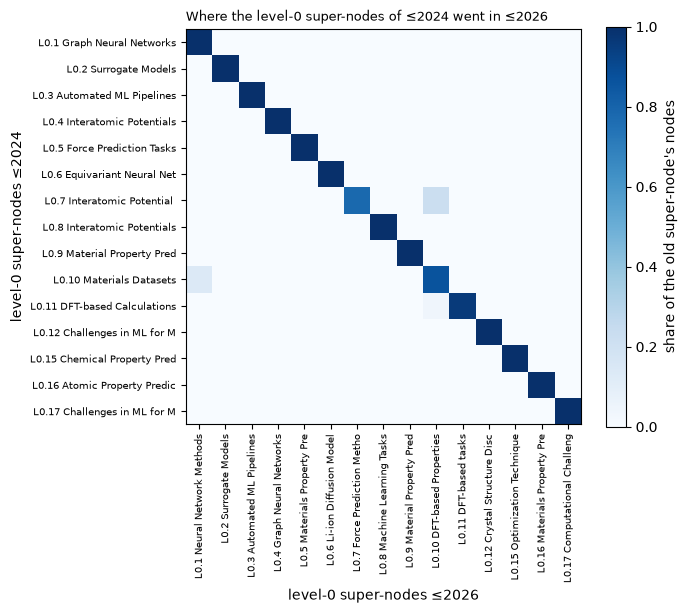

In [13]:
def overlap(c0, c1, level):
    A = {s["id"]: {v for v in s["member_ids"] if is_concept(v)} for s in hier[c0]["supernodes"] if s["level"] == level}
    B = {s["id"]: {v for v in s["member_ids"] if is_concept(v)} for s in hier[c1]["supernodes"] if s["level"] == level}
    common = set().union(*A.values()) & set().union(*B.values())
    return pd.DataFrame({b: {a: len(ma & mb & common) / max(1, len(ma & common)) for a, ma in A.items()} for b, mb in B.items()})

i = list(hier).index(SNAPSHOT)
c0, c1 = (list(hier)[i - 1], SNAPSHOT) if i > 0 else (list(hier)[0], list(hier)[1])
O = overlap(c0, c1, 0)
order_r = sorted(O.index, key=lambda x: int(x[3:]))
order_c = sorted(O.columns, key=lambda x: int(x[3:]))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(O.loc[order_r, order_c].values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(order_c)), [f"{x} {sn[c1][x]['label'][:22]}" for x in order_c], rotation=90, fontsize=7)
ax.set_yticks(range(len(order_r)), [f"{x} {sn[c0][x]['label'][:22]}" for x in order_r], fontsize=7)
ax.set_xlabel(f"level-0 super-nodes ≤{c1}"); ax.set_ylabel(f"level-0 super-nodes ≤{c0}")
fig.colorbar(im, ax=ax, label="share of the old super-node's nodes")
ax.set_title(f"Where the level-0 super-nodes of ≤{c0} went in ≤{c1}", fontsize=9, loc="left")
fig.tight_layout()

In [14]:
rows = []
for k in range(3):
    O = overlap(c0, c1, k)
    rows.append({"level": k, f"super-nodes ≤{c0}": O.shape[0], "median share kept by best successor": O.max(axis=1).median(),
                 "share with ≥ 80% in one successor": (O.max(axis=1) >= 0.8).mean()})
pd.DataFrame(rows).set_index("level").round(3)

,super-nodes ≤2024,median share kept by best successor,share with ≥ 80% in one successor
level,,,
0,15,1.0,0.933
1,60,1.0,0.983
2,240,1.0,0.983


## 6 · One retrieval question traced through the drill-down

The E4 task is to find a question's expected methods among all concept nodes, paying one unit per thing read. The drill-down reads the 15 level-0 profiles and opens the best-scoring one, which reveals its children. Opening a finest-level super-node reads its members. Baselines rank all nodes:
- **flat** by name similarity to the question;
- **PPR**, personalised PageRank on the clustering hypergraph;
- **degree**, popularity, which ignores the question.

Here ties are broken by node id, for a deterministic trace. The reported metrics average over random tie-breaks, so the costs can differ slightly.

In [15]:
from tkh.evaluate.extrinsic import Index, Tree, hierarchy_search, load_questions, ppr_scores, degree_scores
from tkh.evaluate.groundtruth import question_targets, load_ground_truth
from tkh.hierarchy import concept_only
from tkh.evaluate.stability import read_partitions

C4 = max(cfg.cutoffs)  # the ground truth refers to the whole collection
levels = concept_only(read_partitions(OUT, [C4]), tkh)[C4]
index = Index(tkh, C4)
tree = Tree(index, levels)
qs = load_questions(cfg.questions)
tg = question_targets(tkh, load_ground_truth(cfg.ground_truth), CONCEPT_TYPES)[QUESTION]
targets = {v for ids in tg["expected"].values() for v in ids if v in index.pos}
print(QUESTION, qs[QUESTION], "\n")
print("expected methods matched to nodes:", {k: [name[v] for v in ids] for k, ids in tg["expected"].items() if ids})
trace = []
order, costs = hierarchy_search(index, levels, qs[QUESTION], tree=tree, trace=trace)
first = next(c for v, c in zip(order, costs) if v in targets)
print(f"\ndrill-down reaches its first target after {first} reads")

Q3 Which methods (by Feb 2026) are best suited for learning DFT Hamiltonians when dealing with twisted van der Waals heterostructures containing thousands of magnetic atoms? 

expected methods matched to nodes: {'xDeepH': ['deep equivariant neural network method'], 'DeepH-E3': ['DeepH-E3']}

drill-down reaches its first target after 239 reads


In [16]:
lab = {s["id"]: s["label"] for s in hier[C4]["supernodes"]}
contains = lambda g, k: bool(levels[k][g] & targets)
steps = [{"cost": c, "level": k, "super-node": g, "label": lab.get(g) or f"({len(levels[k][g])} nodes, unlabelled)",
          "score": round(sc, 3), "holds a target": "●" if contains(g, k) else ""}
         for c, a, k, g, sc in trace if a == "open" and c <= first]
pd.DataFrame(steps)

,cost,level,super-node,label,score,holds a target
0,15,0,L0.8,Machine Learning Tasks,0.106,
1,21,1,L1.16,Machine Learning Tasks,0.107,
2,26,2,L2.195,"(33 nodes, unlabelled)",0.132,
3,59,0,L0.11,DFT-based tasks,0.071,
4,67,1,L1.48,Defect Analysis,0.092,
5,68,2,L2.187,"(3 nodes, unlabelled)",0.092,
6,71,1,L1.22,Phonon and Defect Calculations,0.065,
7,75,2,L2.50,"(30 nodes, unlabelled)",0.097,
8,105,0,L0.7,Force Prediction Methods,0.065,
9,107,1,L1.66,Free-Energy Techniques,0.078,


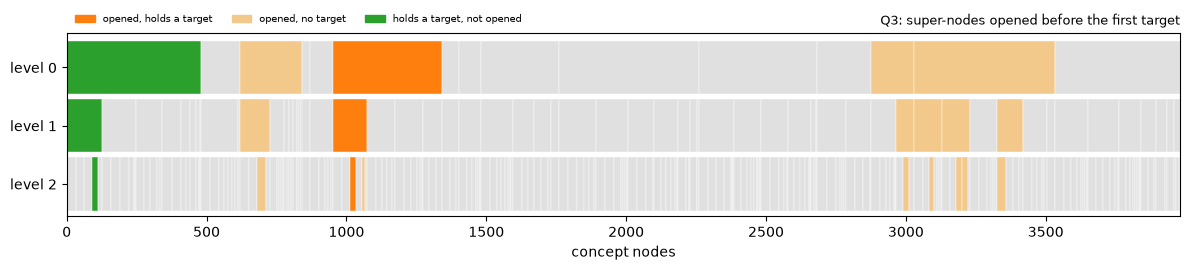

In [17]:
opened = {g for c, a, k, g, sc in trace if a == "open" and c <= first}
on_path = {g for k in range(3) for g in levels[k] if levels[k][g] & targets}
def colour(root, s):
    if s["id"] in opened and s["id"] in on_path: return "C1"
    if s["id"] in opened: return "#f3c98b"
    if s["id"] in on_path: return "C2"
    return "0.88"
concept4 = {v for s in hier[C4]["supernodes"] if s["level"] == 0 for v in s["member_ids"] if is_concept(v)}
fig, ax = plt.subplots(figsize=(12, 2.8))
icicle(ax, hier[C4], concept4, colour, label_level0=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="C1", label="opened, holds a target"), Patch(color="#f3c98b", label="opened, no target"),
                   Patch(color="C2", label="holds a target, not opened")], frameon=False, fontsize=7, ncol=3,
          loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title(f"{QUESTION}: super-nodes opened before the first target", fontsize=9, loc="right")
fig.tight_layout()

,first target at,targets found by 200
method,,
drill-down (SHAC-T),239,0
flat lexical,1389,0
PPR,2,2
degree (ignores question),30,2


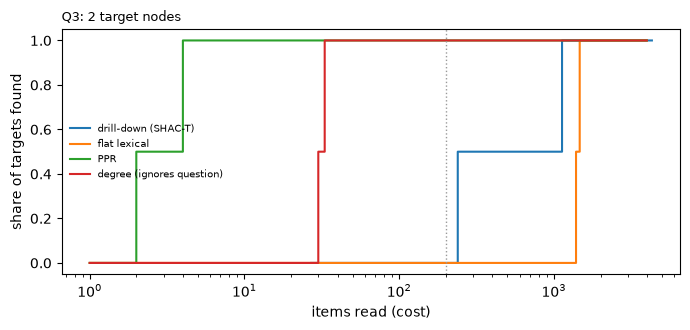

In [18]:
def rank_order(scores):
    return [index.items[i] for i in sorted(range(len(scores)), key=lambda i: (-scores[i], index.items[i]))]

runs = {"drill-down (SHAC-T)": (order, costs),
        "flat lexical": (rank_order(index.query(qs[QUESTION])), None),
        "PPR": (rank_order(ppr_scores(index, tkh, qs[QUESTION])), None),
        "degree (ignores question)": (rank_order(degree_scores(index, tkh)), None)}
fig, ax = plt.subplots(figsize=(7, 3.4))
summary = []
for lbl, (o, c) in runs.items():
    c = c if c is not None else list(range(1, len(o) + 1))
    found = np.cumsum([v in targets for v in o])
    ax.step(c, found / len(targets), where="post", label=lbl)
    summary.append({"method": lbl, "first target at": next(cc for v, cc in zip(o, c) if v in targets),
                    "targets found by 200": int(found[np.searchsorted(c, 200, side="right") - 1]) if c[0] <= 200 else 0})
ax.set_xscale("log"); ax.set_xlabel("items read (cost)"); ax.set_ylabel("share of targets found")
ax.axvline(200, color="0.6", ls=":", lw=1)
ax.legend(frameon=False, fontsize=7); ax.set_title(f"{QUESTION}: {len(targets)} target nodes", fontsize=9, loc="left")
fig.tight_layout()
pd.DataFrame(summary).set_index("method")

**Reading the example (`Q3`).**
- *The drill-down.* It is guided by weak lexical evidence: every profile score is low. It opens three level-0 super-nodes that hold no target before reaching the one that does, then finds DeepH-E3 / xDeepH within it. That is still far cheaper than the flat ranking, where both targets have no lexical match and sit in a huge tie.
- *The baselines.* PPR finds them almost immediately, by walking from the matched task phrases along the paper's star edge. The popularity ranking also beats the drill-down, without reading the question.
- *Aggregate.* This example is favourable to the drill-down. Across all 12 questions it is not significantly better than flat search, and both structure baselines dominate it (`report.md`, E4). `QUESTION = "Q8"` shows a case where the drill-down is worse than flat search.